# Collider, accelerator and beam dump bounds

In [4]:
import sys
!{sys.executable} -m pip install \
"numpy<1.26" \
"pandas<2.0" \
--force-reinstall

import scipy
import numpy as np
print(np.__version__)
print(np.finfo(float).eps)
print(np.__file__)
print(scipy.__version__)
!pip install pandas

  Using cached numpy-1.25.2-cp311-cp311-macosx_11_0_arm64.whl.metadata (5.6 kB)
  Using cached pandas-1.5.3-cp311-cp311-macosx_11_0_arm64.whl.metadata (11 kB)
  Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl.metadata (8.4 kB)
  Using cached pytz-2026.2-py2.py3-none-any.whl.metadata (22 kB)
  Using cached six-1.17.0-py2.py3-none-any.whl.metadata (1.7 kB)
Using cached numpy-1.25.2-cp311-cp311-macosx_11_0_arm64.whl (14.0 MB)
Using cached pandas-1.5.3-cp311-cp311-macosx_11_0_arm64.whl (10.8 MB)
Using cached python_dateutil-2.9.0.post0-py2.py3-none-any.whl (229 kB)
Using cached pytz-2026.2-py2.py3-none-any.whl (510 kB)
Using cached six-1.17.0-py2.py3-none-any.whl (11 kB)
  Attempting uninstall: pytz
    Found existing installation: pytz 2026.2
    Uninstalling pytz-2026.2:
      Successfully uninstalled pytz-2026.2
  Attempting uninstall: six
    Found existing installation: six 1.17.0
    Uninstalling six-1.17.0:
      Successfully uninstalled six-1.17.0━━━━━━━━━━━━━━━━━━━━━

m=   5.0 GeV | r=0 best: cme_91p188   (1.318e-06) | r=-1.5 best: cme_91p188   (1.062e-07)
m=  10.0 GeV | r=0 best: cme_91p188   (1.658e-06) | r=-1.5 best: cme_91p188   (1.336e-07)
m=  25.0 GeV | r=0 best: cme_91p188   (2.359e-06) | r=-1.5 best: cme_91p188   (1.901e-07)
m=  50.0 GeV | r=0 best: cme_91p188   (3.189e-06) | r=-1.5 best: cme_91p188   (2.570e-07)
m=  60.0 GeV | r=0 best: cme_91p188   (4.274e-06) | r=-1.5 best: cme_91p188   (3.444e-07)
m=  70.0 GeV | r=0 best: cme_91p188   (6.788e-06) | r=-1.5 best: cme_91p188   (5.470e-07)
m=  80.0 GeV | r=0 best: cme_240      (2.388e-05) | r=-1.5 best: cme_160      (4.817e-06)
m=  90.0 GeV | r=0 best: cme_365      (2.462e-05) | r=-1.5 best: cme_240      (5.203e-06)
m= 100.0 GeV | r=0 best: cme_240      (2.621e-05) | r=-1.5 best: cme_240      (1.482e-05)
m= 120.0 GeV | r=0 best: cme_365      (2.882e-05) | r=-1.5 best: cme_240      (3.071e-05)
m= 140.0 GeV | r=0 best: cme_365      (3.230e-05) | r=-1.5 best: cme_365      (4.238e-05)
m= 150.0 G

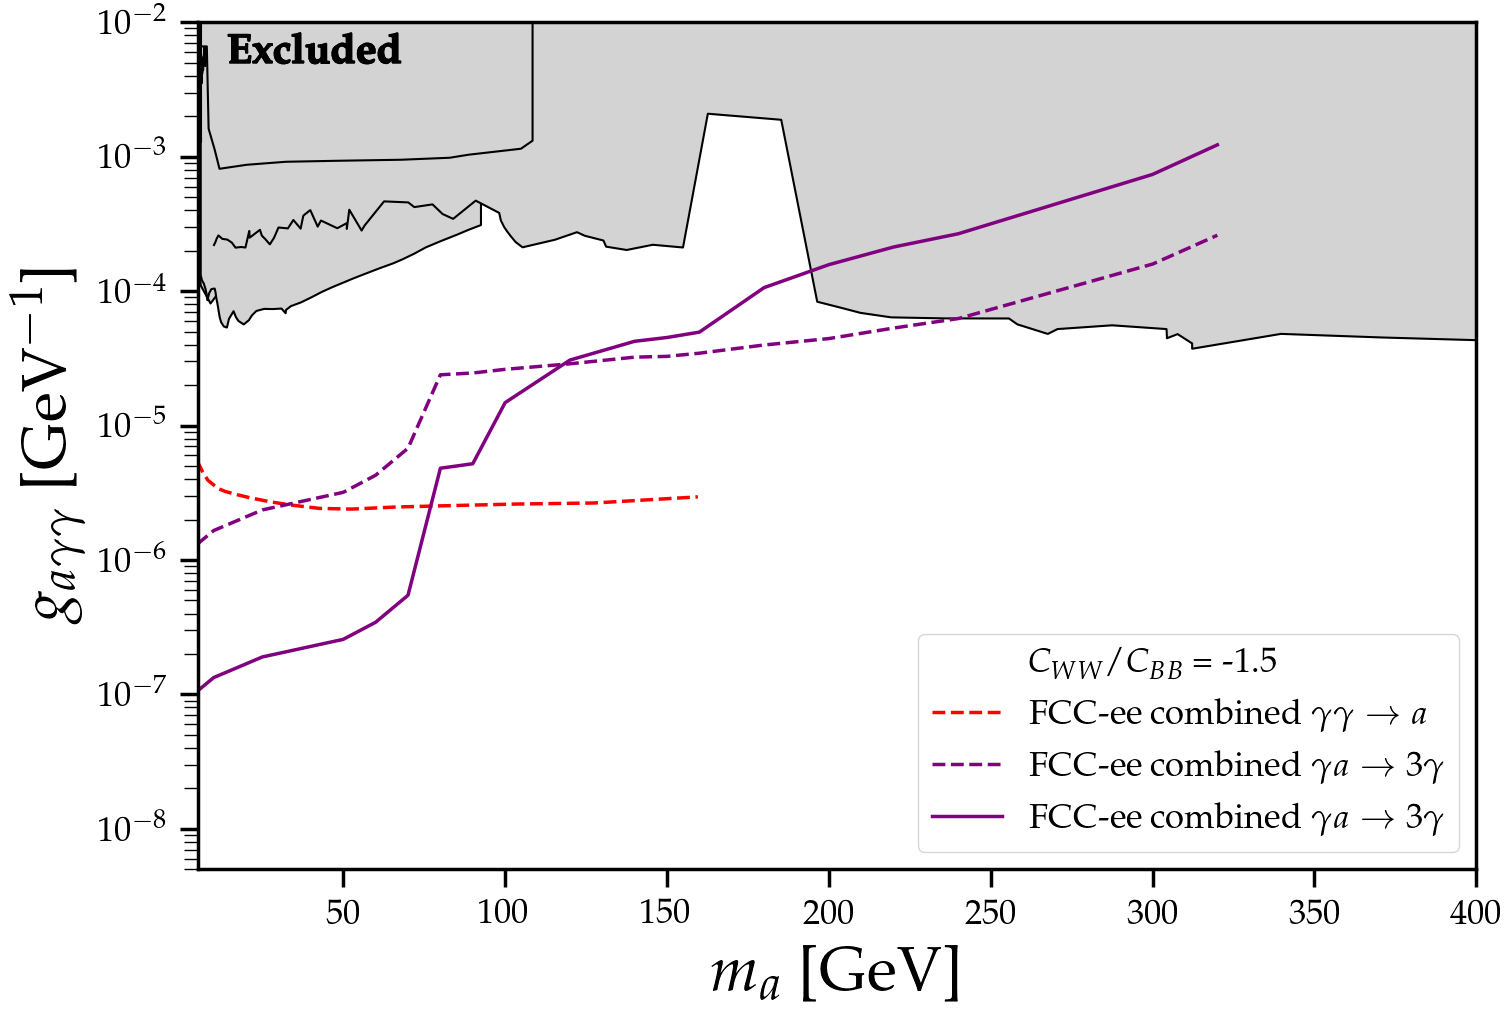

In [9]:
%matplotlib inline
# from numpy import *
import numpy as np
import matplotlib.pyplot as plt
# import PlotFuncs
from PlotFuncs import FigSetup, AxionPhoton, MySaveFig, BlackHoleSpins, FilledLimit, PlotBound, line_background

fig,ax = FigSetup(Shape='Rectangular',xlab=r'$m_a$ [GeV]',ylab=r'$g_{a\gamma\gamma}$ [GeV$^{-1}$]',mathpazo=True,
                  m_min=5e0,m_max=4e2,g_min=5e-9,g_max=1.0e-2,xtick_rotation=0)

ax.set_xscale('linear')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import root_scalar

# constants
alpha = 1/137
alpha_z = 1/127.95
g_v = -0.038
g_a = -0.5
m_z = 91.1876
m_w = 80.36

pi = np.pi

sW2 = 0.223
cW2 = 1-sW2

c_w = np.sqrt(cW2)
s_w = np.sqrt(sW2)

Gamma_z = 2.4952
Lambda = 1000

def BR_bbww(m, CBB, CWW):
    sw2 = sW2
    cw2 = cW2

    # physical combinations
    Cgg = CBB + CWW
    CgZ = cw2 * CWW - sw2 * CBB
    CZZ = cw2 * CWW + sw2 * CBB

    def ps(x):
        return np.sqrt(max(0.0, 1 - x))**3

    # γγ
    g_aa = (4*np.pi*alpha**2/Lambda**2) * m**3 * Cgg**2

    # γZ
    g_aZ = 0
    if m > m_z:
        g_aZ = (8*np.pi*alpha*alpha_z/(sw2*cw2*Lambda**2)) \
               * m**3 * CgZ**2 * ps((m_z/m)**2)

    # ZZ
    g_ZZ = 0
    if m > 2*m_z:
        g_ZZ = (4*np.pi*alpha*alpha_z/(sw2**2*cw2**2*Lambda**2)) \
               * m**3 * CZZ**2 * ps((2*m_z/m)**2)

    # WW
    g_WW = 0
    if m > 2*m_w:
        g_WW = (32*np.pi*alpha**2/(sw2**2 * Lambda**2)) * m**3 * CWW**2 * ps((2*m_w/m)**2)

    tot = g_aa + g_aZ + g_ZZ + g_WW

    return g_aa / tot if tot > 0 else 0

def xsection_bbww(cme, m, CBB, CWW):
    # EW rotation
    sw2 = sW2
    cw2 = cW2

    Cgg = CBB + CWW
    CgZ = cw2 * CWW - sw2 * CBB

    if cme == "zpole":
        s = 91.188**2
        alpha_s = 1/128
    elif cme == "ww":
        s = 160**2
        alpha_s = 1/127.7
    elif cme == "zh":
        s = 240**2
        alpha_s = 1/127.5
    elif cme == "tt":
        s = 365**2
        alpha_s = 1/127.3
    else:
        raise ValueError("Invalid CME")

    sw = np.sqrt(sw2)
    cw = np.sqrt(cw2)

    V = (Cgg/s) + ((1 - 4*sw2)/(4*sw2*cw2)) * (CgZ/(s - m_z**2 + 1j*m_z*Gamma_z))
    A = (1/(4*sw2*cw2)) * (CgZ/(s - m_z**2 + 1j*m_z*Gamma_z))

    M2 = (V*V.conjugate() + A*A.conjugate()).real
    phase = (1 - m*m/s)**3

    xs = (32/3)*np.pi**2*alpha*alpha_s**2*s*s*phase*M2/Lambda**2

    return 389379000 * xs

def XS_BR_bbww(cme, m, CBB, CWW):
    return xsection_bbww(cme, m, CBB, CWW) * BR_bbww(m, CBB, CWW)

def XS_limit(cme, m, g_lim):
    CBB0 = 1000*g_lim/0.367
    return XS_BR_bbww(cme, m, CBB0, 0)
    # return XS_BR(cme, m, CBB0, R=0)

def solve_CBB(cme, m, R, XS_lim):

    def f(CBB):
        return XS_BR_bbww(cme, m, CBB, R * CBB) - XS_lim
        # return XS_BR(cme, m, CBB, R) - XS_lim

    sol = root_scalar(f, bracket=[1e-12, 1e3], method="bisect")
    return sol.root

def gagg_from_CBB(CBB, R):
    return abs(0.367*(1+R)*CBB/1000)

def run_analysis(cme, m, g_lim, R):

    XS_lim = XS_limit(cme, m, g_lim)

    CBB = solve_CBB(cme, m, R, XS_lim)
    g = gagg_from_CBB(CBB, R)

    return g


def combined_all_cmes(ax,c,r):
    import numpy as np

    runs = {
        'cme_91p188': ("limit_data/AxionPhoton/cme_91p188.txt", 'zpole'),
        'cme_160':      ("limit_data/AxionPhoton/cme_160.txt",    'ww'),
        'cme_240':      ("limit_data/AxionPhoton/cme_240.txt",    'zh'),
        'cme_365':      ("limit_data/AxionPhoton/cme_365.txt",    'tt'),
    }

    # --- load data ---
    run_limits = {}
    for run_name, (path, _) in runs.items():
        dat = loadtxt(path)
        x, y = dat[:,0], dat[:,1]
        run_limits[run_name] = {m: lim for m, lim in zip(x, y)}

    all_masses = sorted(set().union(*[d.keys() for d in run_limits.values()]))

    full_x = []
    ref_y = []
    best_r_y = []

    for m in all_masses:
        if m == 230:
            continue
        ref_candidates = []
        r_candidates = []
    
        ref_winner = []
        r_winner = []
    
        for run_name, (_, analysis_type) in runs.items():
            if m in run_limits[run_name]:
                g_lim = run_limits[run_name][m]
    
                ref_candidates.append(g_lim)
                ref_winner.append(run_name)
    
                r_val = run_analysis(analysis_type, m, g_lim, r)
                r_candidates.append(r_val)
                r_winner.append(run_name)
    
        best_ref_val = min(ref_candidates)
        best_ref_run = ref_winner[np.argmin(ref_candidates)]
    
        best_r_val = min(r_candidates)
        best_r_run = r_winner[np.argmin(r_candidates)]
    
        full_x.append(m)
        ref_y.append(best_ref_val)
        best_r_y.append(best_r_val)
    
        print(
            f"m={m:6.1f} GeV | "
            f"r=0 best: {best_ref_run:12s} ({best_ref_val:.3e}) | "
            f"r={r} best: {best_r_run:12s} ({best_r_val:.3e})"
        )
    
    # --- plot ---
    ax.plot(full_x, ref_y, '--', color=c, lw=2.5,
            label=r'{FCC-ee} combined $\gamma a \rightarrow 3\gamma$')

    ax.plot(full_x, best_r_y, '-', color=c, lw=2.5,
            label=r'{FCC-ee} combined $\gamma a \rightarrow 3\gamma$')
    

def g_fusion(ax,c,r):
    dat = loadtxt("limit_data/AxionPhoton/g_fusion.txt")
    x = dat[:,0][:39]
    y = dat[:,1][:39]/(1e3)

    ax.plot(x, y, linestyle='None', label=r'$C_{WW}/C_{BB}$ = ' + str(r[0]))
    ax.plot(x, y, '--', color=c,lw=2.5,label=r'{FCC-ee}  combined  $\gamma \gamma \rightarrow a $')


PlotBound(ax,"limit_data/AxionPhoton/SNe-decay.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/SN1987A_PVO.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/DiffuseGammaRays.txt",scale_x=1e-9,facecolor='lightgrey')

PlotBound(ax,"limit_data/AxionPhoton/BeamDump.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BaBar.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/CMS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/ATLAS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/LHC_pp.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BelleII.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/PrimEx.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/LEP.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BESIII.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/OPAL.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/MiniBooNE.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/GlueX.txt",scale_x=1e-9,facecolor='lightgrey')

plt.text(1.4e1,5.0e-3,r'{\bf Excluded}',color='k',fontsize=30,rotation=0,path_effects=line_background(1,'k'))
plt.text(1.4e1,5.0e-3,r'{\bf Excluded}',color='k',fontsize=30,rotation=0,path_effects=line_background(1,'k'))

g_fusion(ax,'red',[-1.5])
combined_all_cmes(ax, 'purple', -1.5)

ax.legend(loc='lower right')


# runs = {
#     'zpole_91p188': ("limit_data/AxionPhoton/cme_91p188.txt", 'zpole'),
#     'cme_160':      ("limit_data/AxionPhoton/cme_160.txt",    'ww'),
#     'cme_240':      ("limit_data/AxionPhoton/cme_240.txt",    'zh'),
#     'cme_365':      ("limit_data/AxionPhoton/cme_365.txt",    'tt'),
# }

# run_limits = {}
# for run_name, (path, _) in runs.items():
#     dat = loadtxt(path)
#     x, y = dat[:,0], dat[:,1]
#     run_limits[run_name] = {m: lim for m, lim in zip(x, y)}
    
# x = np.arange(-1.5, 1.51, 0.01)
# x_filtered = x[(x < -1.1) | (x > -0.9)]
# print(x_filtered)

# our_limits = []

# m0 = 50  # fixed mass

# for r in x_filtered:

#     candidates = []

#     for run_name, (_, analysis_type) in runs.items():
#         if m0 in run_limits[run_name]:
#             g_lim = run_limits[run_name][m0]
#             val = run_analysis(analysis_type, m0, g_lim, r)
#             candidates.append(val)

#     if not candidates:
#         continue

#     best_val = min(candidates)
#     our_limits.append(best_val)

# print(our_limits)


MySaveFig(fig,'recast_n1p5.pdf')

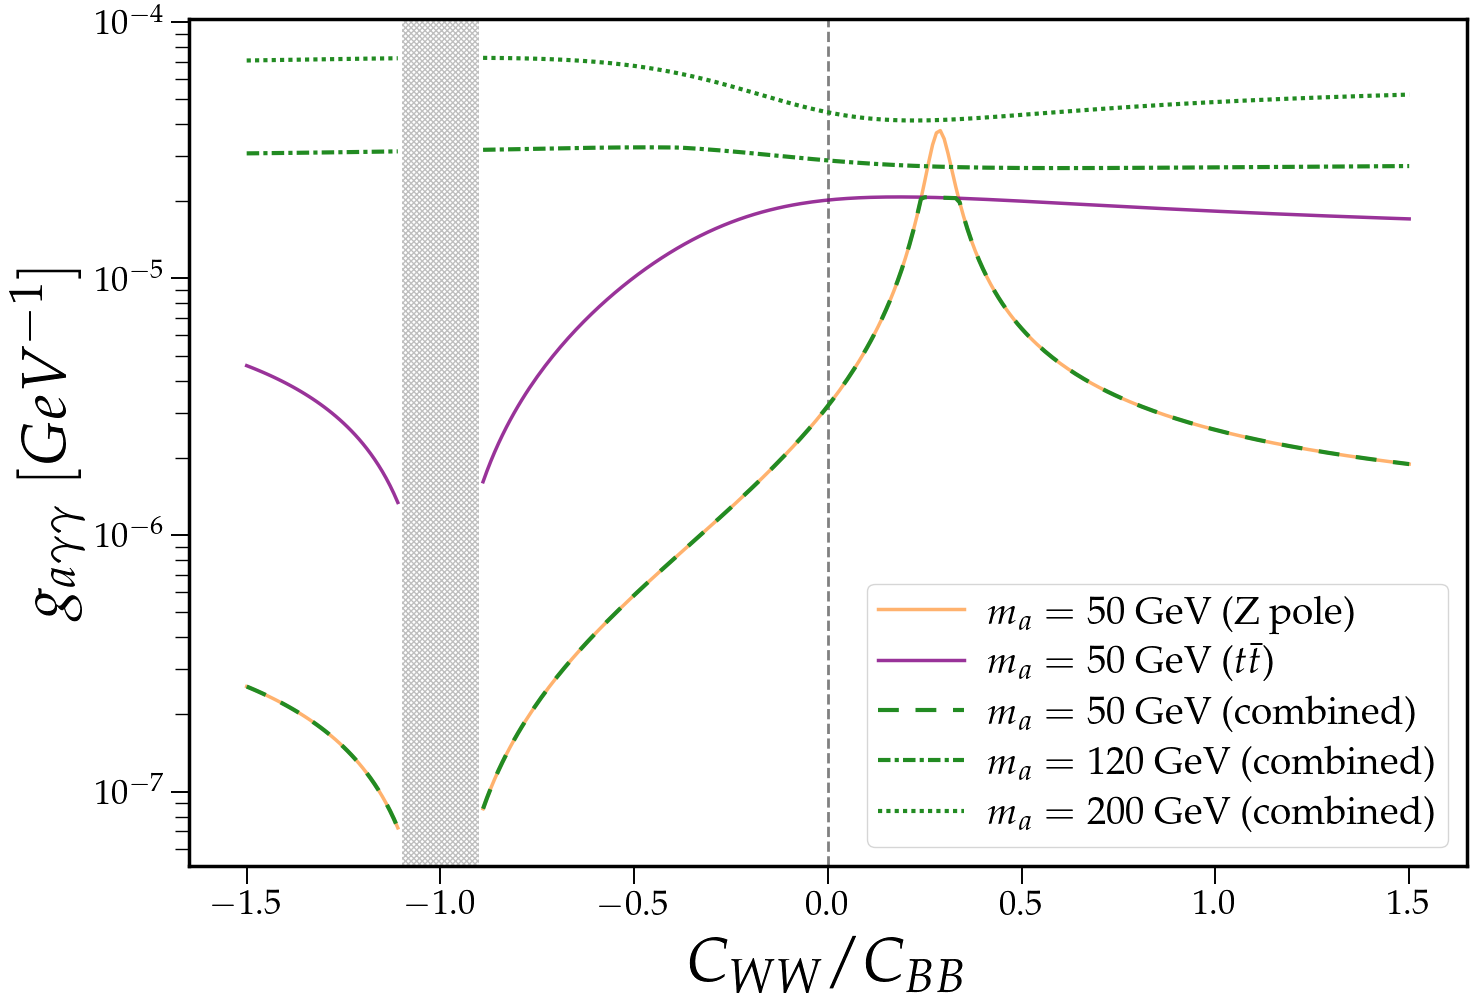

In [10]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import math

x = np.arange(-1.5, 1.51, 0.01)
r = x[(x < -1.1) | (x > -0.9)]

# mass = 50 GeV
limits_50_zpole = [2.569828029429309e-07, 2.5326055239895085e-07, 2.4949616356275525e-07, 2.456889171416653e-07, 2.4183807686692844e-07, 2.3794289008044883e-07, 2.3400258644397988e-07, 2.3001637728720145e-07, 2.2598345605102734e-07, 2.21902996970721e-07, 2.1777415488031851e-07, 2.1359606392182126e-07, 2.0936783831446495e-07, 2.050885695123356e-07, 2.00757328838138e-07, 1.9637316272415855e-07, 1.919350965586104e-07, 1.8744212914428842e-07, 1.828932367013761e-07, 1.7828736792586969e-07, 1.736234464016928e-07, 1.6890036709335128e-07, 1.641169984190479e-07, 1.5927217806533732e-07, 1.543647148516252e-07, 1.493933857313232e-07, 1.4435693662630993e-07, 1.3925407949327785e-07, 1.3408349264969463e-07, 1.288438187919574e-07, 1.2353366421308527e-07, 1.1815159786395017e-07, 1.1269614884989265e-07, 1.0716580667845271e-07, 1.0155901887333175e-07, 9.58741894097774e-08, 9.010967824519903e-08, 8.426379851589902e-08, 7.833481553311143e-08, 7.23209450358484e-08, 7.737790512926859e-08, 8.583881214899321e-08, 9.444470863434252e-08, 1.0319935219102755e-07, 1.1210663169596658e-07, 1.2117057251266876e-07, 1.303953425410793e-07, 1.3978525902365505e-07, 1.4934479535144026e-07, 1.5907858719214244e-07, 1.689914412258999e-07, 1.7908834219908834e-07, 1.893744614905884e-07, 1.9985516614743805e-07, 2.1053602807694606e-07, 2.2142283330399847e-07, 2.3252159391428662e-07, 2.438385573376907e-07, 2.5538021899558484e-07, 2.671533353523347e-07, 2.791649353239496e-07, 2.9142233555915636e-07, 3.0393315499032006e-07, 3.1670533087074853e-07, 3.297471347076898e-07, 3.430671906465597e-07, 3.5667449479393756e-07, 3.7057843499690993e-07, 3.847888114829509e-07, 3.9931586191984043e-07, 4.14170284754507e-07, 4.2936326455979186e-07, 4.4490650176213604e-07, 4.6081224225192114e-07, 4.77093307176349e-07, 4.937631321200111e-07, 5.108357983580757e-07, 5.283260760787795e-07, 5.46249466823613e-07, 5.646222472443894e-07, 5.834615199532351e-07, 6.027852648810807e-07, 6.226123976508431e-07, 6.429628321489915e-07, 6.638575432535732e-07, 6.853186422617016e-07, 7.073694538816569e-07, 7.300345997181414e-07, 7.533400901282225e-07, 7.77313422687779e-07, 8.019836906714805e-07, 8.273817021851887e-07, 8.535401025058211e-07, 8.804935215332853e-07, 9.082787176698766e-07, 9.369347508406313e-07, 9.66503160442219e-07, 9.97028169694712e-07, 1.0285568996939711e-06, 1.0611396165556397e-06, 1.0948299930318268e-06, 1.1296854033889015e-06, 1.1657672498905112e-06, 1.203141317860901e-06, 1.2418781770086906e-06, 1.2820536201058316e-06, 1.3237491576015584e-06, 1.3670525644292908e-06, 1.4120584918232922e-06, 1.4588691559448934e-06, 1.5075951034356239e-06, 1.5583560768319036e-06, 1.6112819928927893e-06, 1.6665140389648958e-06, 1.724205917594593e-06, 1.784525270784099e-06, 1.8476552804753844e-06, 1.913796514326611e-06, 1.983169030562754e-06, 2.0560147939760162e-06, 2.132600464461097e-06, 2.2132206186880744e-06, 2.2982014870552e-06, 2.387905304088155e-06, 2.482735394886409e-06, 2.583142147650227e-06, 2.689630049128942e-06, 2.8027660135756613e-06, 2.9231892935278322e-06, 3.0516233353652696e-06, 3.1888900106579913e-06, 3.3359268357854775e-06, 3.493807894530497e-06, 3.6637694433312464e-06, 3.847241440166278e-06, 4.045886660453639e-06, 4.261649570724265e-06, 4.496817911155366e-06, 4.754100934761517e-06, 5.03672973352701e-06, 5.3485871428566214e-06, 5.69437767369191e-06, 6.079852310385611e-06, 6.512109320250679e-06, 7.000001802168733e-06, 7.554696876768652e-06, 8.190453021501476e-06, 8.925714404832265e-06, 9.784669213221329e-06, 1.0799486955164301e-05, 1.201353344306484e-05, 1.3485919561593394e-05, 1.5297586136039806e-05, 1.7558078910926073e-05, 2.040787698553556e-05, 2.399622660350343e-05, 2.837096178861931e-05, 3.3141389149216953e-05, 3.692313564506004e-05, 3.76765917443243e-05, 3.49944358883002e-05, 3.066489437082798e-05, 2.6362272535516306e-05, 2.272076208286573e-05, 1.979347672806112e-05, 1.746193512957331e-05, 1.5592023279466966e-05, 1.4073463605796941e-05, 1.2823046166409875e-05, 1.1779451700803047e-05, 1.0897527001191498e-05, 1.0143739023640885e-05, 9.49287922815983e-06, 8.92574215190321e-06, 8.427498754327993e-06, 7.986550880463605e-06, 7.593716710293316e-06, 7.241644744188449e-06, 6.924386967302589e-06, 6.63708404150247e-06, 6.375730336556638e-06, 6.136996485350217e-06, 5.918093932273856e-06, 5.7166704230497935e-06, 5.5307286186043365e-06, 5.358562111632608e-06, 5.198704689585904e-06, 5.049889792899686e-06, 4.9110178557785615e-06, 4.781129817666759e-06, 4.659385494595662e-06, 4.545045807542254e-06, 4.437458080640647e-06, 4.336043842660423e-06, 4.24028859750093e-06, 4.149733265616265e-06, 4.0639669417770475e-06, 3.982620756394327e-06, 3.9053626599663935e-06, 3.831892938735438e-06, 3.7619404044586077e-06, 3.6952590739818455e-06, 3.6316253166597023e-06, 3.570835388978276e-06, 3.512703264029875e-06, 3.457058756387007e-06, 3.4037458779396357e-06, 3.352621388918168e-06, 3.3035535223801083e-06, 3.256420858977991e-06, 3.2111113391005206e-06, 3.1675213749404585e-06, 3.125555063401956e-06, 3.085123493393299e-06, 3.0461441213368606e-06, 3.008540206669013e-06, 2.9722403155572523e-06, 2.9371778695739386e-06, 2.9032907369797085e-06, 2.8705208788466573e-06, 2.8388140007359037e-06, 2.808119277990288e-06, 2.778389057792547e-06, 2.7495786433136144e-06, 2.7216460394757104e-06, 2.6945517788237173e-06, 2.6682587183468717e-06, 2.642731870735022e-06, 2.6179382587129633e-06, 2.5938467701961962e-06, 2.5704280223649884e-06, 2.5476542535494704e-06, 2.5254992019719633e-06, 2.503938013421655e-06, 2.4829471497898034e-06, 2.462504290629371e-06, 2.4425882733084973e-06, 2.4231790084430525e-06, 2.404257410558112e-06, 2.3858053391671587e-06, 2.3678055507253605e-06, 2.350241626148775e-06, 2.333097933980706e-06, 2.3163595832707062e-06, 2.3000123714728986e-06, 2.2840427609115563e-06, 2.2684378228591514e-06, 2.2531852132978578e-06, 2.238273144508749e-06, 2.2236903438311547e-06, 2.2094260279116997e-06, 2.195469884346156e-06, 2.1818120407261394e-06, 2.1684430323558844e-06, 2.1553538036864774e-06, 2.1425356682877816e-06, 2.1299802879608302e-06, 2.117679677549016e-06, 2.105626158977525e-06, 2.0938123674726764e-06, 2.0822312216386614e-06, 2.0708759255697764e-06, 2.059739931403964e-06, 2.048816955307967e-06, 2.0381009448029458e-06, 2.0275860756352525e-06, 2.0172667360259706e-06, 2.007137528835298e-06, 1.9971932487452448e-06, 1.987428877357172e-06, 1.9778395811056384e-06, 1.968420690083943e-06, 1.9591677077186605e-06, 1.9500762888389545e-06, 1.9411422424928847e-06, 1.9323615155189463e-06, 1.9237301980222244e-06, 1.915244509527551e-06, 1.9069007975974275e-06, 1.8986955265537565e-06, 1.8906252853661104e-06]
limits_50_tt = [4.57306463353788e-06, 4.511484804633211e-06, 4.449036399993471e-06, 4.385702771422918e-06, 4.321466896339484e-06, 4.256311369495369e-06, 4.190218397566068e-06, 4.123169787181074e-06, 4.055146938900106e-06, 3.986130836065226e-06, 3.916102038737958e-06, 3.84504067122148e-06, 3.7729264181360486e-06, 3.699738509737697e-06, 3.625455718110996e-06, 3.5500563445217606e-06, 3.4735182128717353e-06, 3.395818659124405e-06, 3.3169345233645765e-06, 3.2368421408018374e-06, 3.1555173343386362e-06, 3.0729354038917864e-06, 2.9890711194951186e-06, 2.9038987135807124e-06, 2.817391873051516e-06, 2.7295237313278836e-06, 2.640266862115193e-06, 2.549593272219656e-06, 2.457474396450276e-06, 2.363881090956201e-06, 2.268783629380375e-06, 2.1721516988045793e-06, 2.0739543958509283e-06, 1.9741602248564924e-06, 1.8727370961782932e-06, 1.7696523268452273e-06, 1.664872640636299e-06, 1.5583641713793474e-06, 1.4500924661715492e-06, 1.340022491585723e-06, 1.4542033500094998e-06, 1.6136326524433281e-06, 1.7757711228809751e-06, 1.9406577058962283e-06, 2.1083305126184864e-06, 2.278826670660095e-06, 2.452182162960988e-06, 2.6284316545206038e-06, 2.807608306378192e-06, 2.98974357843219e-06, 3.1748670168481465e-06, 3.363006029067073e-06, 3.554185645644942e-06, 3.748428266041856e-06, 3.945753391424895e-06, 4.1461773430374015e-06, 4.349712966199882e-06, 4.556369318351828e-06, 4.766151347158236e-06, 4.9790595499450575e-06, 5.195089626093869e-06, 5.414232112004136e-06, 5.6364720101360115e-06, 5.861788405692666e-06, 6.090154077148477e-06, 6.321535099619107e-06, 6.555890445649944e-06, 6.7931715859393834e-06, 7.033322089253696e-06, 7.276277232472787e-06, 7.521963613347972e-06, 7.770298782126376e-06, 8.021190888665042e-06, 8.274538348711561e-06, 8.530229544136867e-06, 8.788142548866817e-06, 9.048144899353155e-06, 9.310093403664398e-06, 9.573834007059313e-06, 9.839201708749401e-06, 1.0106020543645055e-05, 1.0374103631810425e-05, 1.0643253302680829e-05, 1.091326129657214e-05, 1.1183909052635154e-05, 1.1454968084428404e-05, 1.1726200445117353e-05, 1.199735928612021e-05, 1.2268189518209975e-05, 1.253842855547587e-05, 1.2807807163018774e-05, 1.3076050395172666e-05, 1.3342878613599675e-05, 1.3608008595937222e-05, 1.3871154713549013e-05, 1.4132030176045954e-05, 1.4390348330568624e-05, 1.4645824008581872e-05, 1.4898174898120499e-05, 1.5147122936922538e-05, 1.5392395710021714e-05, 1.563372782753444e-05, 1.587086228539256e-05, 1.6103551773896133e-05, 1.6331559933460492e-05, 1.655466253244545e-05, 1.677264856594537e-05, 1.6985321250258523e-05, 1.7192498905408252e-05, 1.7394015729731736e-05, 1.7589722434461815e-05, 1.7779486755682084e-05, 1.7963193830708087e-05, 1.8140746427694613e-05, 1.83120650553934e-05, 1.8477087924689725e-05, 1.8635770787525244e-05, 1.878808665471968e-05, 1.8934025392534818e-05, 1.9073593221450033e-05, 1.9206812106744742e-05, 1.9333719077212806e-05, 1.945436545659752e-05, 1.9568816044333086e-05, 1.967714823638735e-05, 1.9779451111982962e-05, 1.987582449278126e-05, 1.9966377981426288e-05, 2.0051229999436893e-05, 2.0130506825137948e-05, 2.0204341642439526e-05, 2.027287360916081e-05, 2.0336246957897894e-05, 2.0394610118887566e-05, 2.0448114888323072e-05, 2.049691563965774e-05, 2.0541168566513797e-05, 2.0581030990600973e-05, 2.06166607068729e-05, 2.0648215374018278e-05, 2.067585197160462e-05, 2.069972628855343e-05, 2.07199924704188e-05, 2.0736802609041036e-05, 2.0750306383441434e-05, 2.0760650738750192e-05, 2.076797960847419e-05, 2.0772433676466907e-05, 2.0774150179161053e-05, 2.0773262740762438e-05, 2.0769901233477705e-05, 2.076419167630981e-05, 2.0756256164519934e-05, 2.0746212803587717e-05, 2.073417569571644e-05, 2.0720254920862053e-05, 2.070455654569063e-05, 2.068718265466202e-05, 2.0668231380331245e-05, 2.0647796965685375e-05, 2.0625969818839856e-05, 2.0602836589652503e-05, 2.0578480244616408e-05, 2.0552980154817375e-05, 2.052641219346162e-05, 2.04988488216688e-05, 2.047035919671732e-05, 2.0441009265777832e-05, 2.0410861879751985e-05, 2.0379976885988944e-05, 2.0348411240220522e-05, 2.0316219106918254e-05, 2.0283451971045983e-05, 2.025015873333191e-05, 2.0216385808435127e-05, 2.0182177238966983e-05, 2.0147574778141825e-05, 2.011261799664026e-05, 2.0077344364334192e-05, 2.0041789351947673e-05, 2.000598651613289e-05, 1.996996758261638e-05, 1.993376252903239e-05, 1.989739966716946e-05, 1.9860905716324788e-05, 1.982430588733714e-05, 1.9787623938925986e-05, 1.9750882264240806e-05, 1.9714101938764397e-05, 1.9677302802285665e-05, 1.9640503503295587e-05, 1.960372157115505e-05, 1.956697346009967e-05, 1.953027461684423e-05, 1.9493639512826753e-05, 1.9457081714746576e-05, 1.9420613912701335e-05, 1.938424797586122e-05, 1.9347994992966396e-05, 1.931186530573156e-05, 1.927586856360741e-05, 1.9240013740522136e-05, 1.920430918820862e-05, 1.9168762653141432e-05, 1.9133381323592627e-05, 1.9098171848667897e-05, 1.906314037403196e-05, 1.9028292567268322e-05, 1.8993633639379748e-05, 1.8959168376250035e-05, 1.892490115930998e-05, 1.8890835986750935e-05, 1.885697649528602e-05, 1.882332598007287e-05, 1.878988741990396e-05, 1.8756663481313694e-05, 1.8723656554134292e-05, 1.869086874654119e-05, 1.8658301923829396e-05, 1.862595770385005e-05, 1.859383747930616e-05, 1.8561942430556402e-05, 1.8530273541078728e-05, 1.8498831600586517e-05, 1.8467617225694594e-05, 1.8436630863178792e-05, 1.840587280585684e-05, 1.8375343195860978e-05, 1.834504204582546e-05, 1.83149692293294e-05, 1.8285124504691918e-05, 1.8255507513029422e-05, 1.8226117794436333e-05, 1.8196954785872872e-05, 1.8168017832039122e-05, 1.8139306190981566e-05, 1.811081904499322e-05, 1.8082555492699332e-05, 1.8054514567793615e-05, 1.8026695239012177e-05, 1.7999096415348902e-05, 1.7971716948441493e-05, 1.7944555637565214e-05, 1.7917611237325553e-05, 1.7890882454190006e-05, 1.7864367959526544e-05, 1.7838066380268074e-05, 1.7811976320230302e-05, 1.7786096342027403e-05, 1.776042498540411e-05, 1.7734960760064537e-05, 1.770970216116187e-05, 1.7684647656077384e-05, 1.7659795693912436e-05, 1.7635144712138082e-05, 1.7610693128576408e-05, 1.7586439356564267e-05, 1.7562381784834957e-05, 1.7538518810205612e-05, 1.7514848808266758e-05, 1.7491370157112284e-05, 1.7468081225396268e-05, 1.7444980381094765e-05, 1.7422065988194073e-05, 1.7399336409246245e-05, 1.7376790007846427e-05, 1.7354425154108994e-05, 1.7332240208512887e-05, 1.7310233545540354e-05, 1.728840353727458e-05, 1.7266748561483507e-05, 1.7245267003497388e-05, 1.722395724854216e-05, 1.7202817695938347e-05, 1.7181846748083542e-05, 1.716104281182145e-05, 1.7140404309355088e-05, 1.711992966677293e-05, 1.709961732158514e-05, 1.7079465720598307e-05, 1.7059473314374087e-05]
limits_50_combined = [2.569828029429309e-07, 2.5326055239895085e-07, 2.4949616356275525e-07, 2.456889171416653e-07, 2.4183807686692844e-07, 2.3794289008044883e-07, 2.3400258644397988e-07, 2.3001637728720145e-07, 2.2598345605102734e-07, 2.21902996970721e-07, 2.1777415488031851e-07, 2.1359606392182126e-07, 2.0936783831446495e-07, 2.050885695123356e-07, 2.00757328838138e-07, 1.9637316272415855e-07, 1.919350965586104e-07, 1.8744212914428842e-07, 1.828932367013761e-07, 1.7828736792586969e-07, 1.736234464016928e-07, 1.6890036709335128e-07, 1.641169984190479e-07, 1.5927217806533732e-07, 1.543647148516252e-07, 1.493933857313232e-07, 1.4435693662630993e-07, 1.3925407949327785e-07, 1.3408349264969463e-07, 1.288438187919574e-07, 1.2353366421308527e-07, 1.1815159786395017e-07, 1.1269614884989265e-07, 1.0716580667845271e-07, 1.0155901887333175e-07, 9.58741894097774e-08, 9.010967824519903e-08, 8.426379851589902e-08, 7.833481553311143e-08, 7.23209450358484e-08, 7.737790512926859e-08, 8.583881214899321e-08, 9.444470863434252e-08, 1.0319935219102755e-07, 1.1210663169596658e-07, 1.2117057251266876e-07, 1.303953425410793e-07, 1.3978525902365505e-07, 1.4934479535144026e-07, 1.5907858719214244e-07, 1.689914412258999e-07, 1.7908834219908834e-07, 1.893744614905884e-07, 1.9985516614743805e-07, 2.1053602807694606e-07, 2.2142283330399847e-07, 2.3252159391428662e-07, 2.438385573376907e-07, 2.5538021899558484e-07, 2.671533353523347e-07, 2.791649353239496e-07, 2.9142233555915636e-07, 3.0393315499032006e-07, 3.1670533087074853e-07, 3.297471347076898e-07, 3.430671906465597e-07, 3.5667449479393756e-07, 3.7057843499690993e-07, 3.847888114829509e-07, 3.9931586191984043e-07, 4.14170284754507e-07, 4.2936326455979186e-07, 4.4490650176213604e-07, 4.6081224225192114e-07, 4.77093307176349e-07, 4.937631321200111e-07, 5.108357983580757e-07, 5.283260760787795e-07, 5.46249466823613e-07, 5.646222472443894e-07, 5.834615199532351e-07, 6.027852648810807e-07, 6.226123976508431e-07, 6.429628321489915e-07, 6.638575432535732e-07, 6.853186422617016e-07, 7.073694538816569e-07, 7.300345997181414e-07, 7.533400901282225e-07, 7.77313422687779e-07, 8.019836906714805e-07, 8.273817021851887e-07, 8.535401025058211e-07, 8.804935215332853e-07, 9.082787176698766e-07, 9.369347508406313e-07, 9.66503160442219e-07, 9.97028169694712e-07, 1.0285568996939711e-06, 1.0611396165556397e-06, 1.0948299930318268e-06, 1.1296854033889015e-06, 1.1657672498905112e-06, 1.203141317860901e-06, 1.2418781770086906e-06, 1.2820536201058316e-06, 1.3237491576015584e-06, 1.3670525644292908e-06, 1.4120584918232922e-06, 1.4588691559448934e-06, 1.5075951034356239e-06, 1.5583560768319036e-06, 1.6112819928927893e-06, 1.6665140389648958e-06, 1.724205917594593e-06, 1.784525270784099e-06, 1.8476552804753844e-06, 1.913796514326611e-06, 1.983169030562754e-06, 2.0560147939760162e-06, 2.132600464461097e-06, 2.2132206186880744e-06, 2.2982014870552e-06, 2.387905304088155e-06, 2.482735394886409e-06, 2.583142147650227e-06, 2.689630049128942e-06, 2.8027660135756613e-06, 2.9231892935278322e-06, 3.0516233353652696e-06, 3.1888900106579913e-06, 3.3359268357854775e-06, 3.493807894530497e-06, 3.6637694433312464e-06, 3.847241440166278e-06, 4.045886660453639e-06, 4.261649570724265e-06, 4.496817911155366e-06, 4.754100934761517e-06, 5.03672973352701e-06, 5.3485871428566214e-06, 5.69437767369191e-06, 6.079852310385611e-06, 6.512109320250679e-06, 7.000001802168733e-06, 7.554696876768652e-06, 8.190453021501476e-06, 8.925714404832265e-06, 9.784669213221329e-06, 1.0799486955164301e-05, 1.201353344306484e-05, 1.3485919561593394e-05, 1.5297586136039806e-05, 1.7558078910926073e-05, 2.040787698553556e-05, 2.0720254920862053e-05, 2.070455654569063e-05, 2.068718265466202e-05, 2.0668231380331245e-05, 2.0647796965685375e-05, 2.0625969818839856e-05, 2.0602836589652503e-05, 2.0578480244616408e-05, 2.0552980154817375e-05, 1.979347672806112e-05, 1.746193512957331e-05, 1.5592023279466966e-05, 1.4073463605796941e-05, 1.2823046166409875e-05, 1.1779451700803047e-05, 1.0897527001191498e-05, 1.0143739023640885e-05, 9.49287922815983e-06, 8.92574215190321e-06, 8.427498754327993e-06, 7.986550880463605e-06, 7.593716710293316e-06, 7.241644744188449e-06, 6.924386967302589e-06, 6.63708404150247e-06, 6.375730336556638e-06, 6.136996485350217e-06, 5.918093932273856e-06, 5.7166704230497935e-06, 5.5307286186043365e-06, 5.358562111632608e-06, 5.198704689585904e-06, 5.049889792899686e-06, 4.9110178557785615e-06, 4.781129817666759e-06, 4.659385494595662e-06, 4.545045807542254e-06, 4.437458080640647e-06, 4.336043842660423e-06, 4.24028859750093e-06, 4.149733265616265e-06, 4.0639669417770475e-06, 3.982620756394327e-06, 3.9053626599663935e-06, 3.831892938735438e-06, 3.7619404044586077e-06, 3.6952590739818455e-06, 3.6316253166597023e-06, 3.570835388978276e-06, 3.512703264029875e-06, 3.457058756387007e-06, 3.4037458779396357e-06, 3.352621388918168e-06, 3.3035535223801083e-06, 3.256420858977991e-06, 3.2111113391005206e-06, 3.1675213749404585e-06, 3.125555063401956e-06, 3.085123493393299e-06, 3.0461441213368606e-06, 3.008540206669013e-06, 2.9722403155572523e-06, 2.9371778695739386e-06, 2.9032907369797085e-06, 2.8705208788466573e-06, 2.8388140007359037e-06, 2.808119277990288e-06, 2.778389057792547e-06, 2.7495786433136144e-06, 2.7216460394757104e-06, 2.6945517788237173e-06, 2.6682587183468717e-06, 2.642731870735022e-06, 2.6179382587129633e-06, 2.5938467701961962e-06, 2.5704280223649884e-06, 2.5476542535494704e-06, 2.5254992019719633e-06, 2.503938013421655e-06, 2.4829471497898034e-06, 2.462504290629371e-06, 2.4425882733084973e-06, 2.4231790084430525e-06, 2.404257410558112e-06, 2.3858053391671587e-06, 2.3678055507253605e-06, 2.350241626148775e-06, 2.333097933980706e-06, 2.3163595832707062e-06, 2.3000123714728986e-06, 2.2840427609115563e-06, 2.2684378228591514e-06, 2.2531852132978578e-06, 2.238273144508749e-06, 2.2236903438311547e-06, 2.2094260279116997e-06, 2.195469884346156e-06, 2.1818120407261394e-06, 2.1684430323558844e-06, 2.1553538036864774e-06, 2.1425356682877816e-06, 2.1299802879608302e-06, 2.117679677549016e-06, 2.105626158977525e-06, 2.0938123674726764e-06, 2.0822312216386614e-06, 2.0708759255697764e-06, 2.059739931403964e-06, 2.048816955307967e-06, 2.0381009448029458e-06, 2.0275860756352525e-06, 2.0172667360259706e-06, 2.007137528835298e-06, 1.9971932487452448e-06, 1.987428877357172e-06, 1.9778395811056384e-06, 1.968420690083943e-06, 1.9591677077186605e-06, 1.9500762888389545e-06, 1.9411422424928847e-06, 1.9323615155189463e-06, 1.9237301980222244e-06, 1.915244509527551e-06, 1.9069007975974275e-06, 1.8986955265537565e-06, 1.8906252853661104e-06]

# mass = 120 GeV
limits_120 = [3.071321834070379e-05, 3.0724540403722015e-05, 3.0735997584266864e-05, 3.074759174141401e-05, 3.075932474639095e-05, 3.07711984847936e-05, 3.0783214855308444e-05, 3.079537576645299e-05, 3.08076831380882e-05, 3.0820138897415704e-05, 3.0832744979303716e-05, 3.0845503323796745e-05, 3.085841587464221e-05, 3.087148457580918e-05, 3.088471137137104e-05, 3.089809820263702e-05, 3.0911647004918665e-05, 3.092535970425715e-05, 3.093923821600215e-05, 3.0953284440626434e-05, 3.0967500260792227e-05, 3.098188753616195e-05, 3.0996448101520604e-05, 3.101118376055649e-05, 3.1026096281675826e-05, 3.104118739376525e-05, 3.1056458779607446e-05, 3.1071912071148114e-05, 3.108754884223358e-05, 3.110337060228715e-05, 3.111937878959431e-05, 3.113557476295807e-05, 3.115195979374555e-05, 3.116853505760855e-05, 3.118530162401364e-05, 3.120226044737604e-05, 3.12194123549599e-05, 3.123675803719075e-05, 3.1254298033978155e-05, 3.127203272219877e-05, 3.168745141503961e-05, 3.170900274220636e-05, 3.17306664408122e-05, 3.1752432082932154e-05, 3.1774288339240394e-05, 3.1796222927508374e-05, 3.1818222559147075e-05, 3.184027288435426e-05, 3.186235843397599e-05, 3.188446256282838e-05, 3.190656738848212e-05, 3.192865373016416e-05, 3.195070104695551e-05, 3.197268737527175e-05, 3.199458926477905e-05, 3.2016381714831665e-05, 3.203803811247405e-05, 3.2059530168604594e-05, 3.2080827857868274e-05, 3.210189935960555e-05, 3.212271100146094e-05, 3.214322720490841e-05, 3.216341043820858e-05, 3.2183221171673735e-05, 3.220261783937397e-05, 3.2221556809474595e-05, 3.223999236169269e-05, 3.225787667536691e-05, 3.227515982647167e-05, 3.229178979898667e-05, 3.230771251019153e-05, 3.232287185082423e-05, 3.2337209739555793e-05, 3.235066620229021e-05, 3.236317946426808e-05, 3.237468607099838e-05, 3.238512102538385e-05, 3.2394417955865056e-05, 3.240250930912876e-05, 3.240932656418639e-05, 3.241480048473345e-05, 3.24188613932961e-05, 3.242143947549671e-05, 3.2422465116745976e-05, 3.242186926647221e-05, 3.241958382894924e-05, 3.24155420829131e-05, 3.240967912660378e-05, 3.240193234643261e-05, 3.239224189924883e-05, 3.238055121862291e-05, 3.236680752732324e-05, 3.2331859239725925e-05, 3.226718360285901e-05, 3.219956944752723e-05, 3.212906213719e-05, 3.2055718313261015e-05, 3.197960597444728e-05, 3.190080447470205e-05, 3.1819404413297644e-05, 3.173550742431944e-05, 3.164922586833247e-05, 3.156068241655882e-05, 3.1470009535610754e-05, 3.1377348876026173e-05, 3.128285056551887e-05, 3.1186672426214606e-05, 3.1088979102639023e-05, 3.0989941132205877e-05, 3.088973396216931e-05, 3.0788536910849884e-05, 3.0686532113840184e-05, 3.058390344001339e-05, 3.0480835408040396e-05, 3.037751211080816e-05, 3.0274116162368565e-05, 3.017082767777024e-05, 3.0067823294782987e-05, 2.996527525539047e-05, 2.9863350548042134e-05, 2.9762210124693748e-05, 2.966200818907702e-05, 2.9562891577672658e-05, 2.9464999215784988e-05, 2.9368461670283692e-05, 2.927340078570038e-05, 2.917992940841306e-05, 2.908815119575003e-05, 2.8998160507183956e-05, 2.891004237137063e-05, 2.8823872529567052e-05, 2.8739717543694184e-05, 2.8657634966593123e-05, 2.8577673563444245e-05, 2.8499873587087295e-05, 2.842426709629018e-05, 2.8350878293914446e-05, 2.827972392143298e-05, 2.821081364758039e-05, 2.814415049070783e-05, 2.807973125146426e-05, 2.8017546946572942e-05, 2.7957583245528568e-05, 2.7899820912248956e-05, 2.7844236231628287e-05, 2.779080143107046e-05, 2.773948509430373e-05, 2.7690252553994764e-05, 2.764306627346261e-05, 2.7597886208456777e-05, 2.7554670158217803e-05, 2.751337408263773e-05, 2.7473952413370805e-05, 2.7436358339010655e-05, 2.7400544075533994e-05, 2.7366461103079064e-05, 2.7334060403193413e-05, 2.7303292658465776e-05, 2.7274108454165807e-05, 2.7246458433297477e-05, 2.7220293472096712e-05, 2.7195564800389397e-05, 2.717222414142888e-05, 2.7150223810062527e-05, 2.712951682138117e-05, 2.7110056959627414e-05, 2.70917988676003e-05, 2.7074698091833616e-05, 2.705871115171272e-05, 2.704379556521252e-05, 2.7029909898704296e-05, 2.701701377987693e-05, 2.7005067927764365e-05, 2.699403416564073e-05, 2.6983875421867774e-05, 2.697455574488914e-05, 2.6966040287688495e-05, 2.6958295314191424e-05, 2.695128818845655e-05, 2.6944987357764648e-05, 2.6939362341340367e-05, 2.6934383717378977e-05, 2.6930023094687737e-05, 2.692625310439339e-05, 2.6923047368728117e-05, 2.692038048447071e-05, 2.6918227993479645e-05, 2.6916566360423354e-05, 2.6915372954135276e-05, 2.691462600808124e-05, 2.6914304613449086e-05, 2.6914388675130787e-05, 2.691485889672826e-05, 2.6915696757788207e-05, 2.69168844745303e-05, 2.691840499085058e-05, 2.692024194045782e-05, 2.6922379637837884e-05, 2.6924803035891735e-05, 2.6927497717277923e-05, 2.693044986338102e-05, 2.6933646237987535e-05, 2.6937074159487856e-05, 2.6940721486051536e-05, 2.6944576589459126e-05, 2.6948628340042733e-05, 2.6952866082630074e-05, 2.6957279619372832e-05, 2.6961859195182667e-05, 2.69665954742881e-05, 2.697147953345451e-05, 2.6976502827758154e-05, 2.6981657194354297e-05, 2.698693482420984e-05, 2.699232825579271e-05, 2.6997830350624718e-05, 2.7003434288861538e-05, 2.7009133556462888e-05, 2.7014921926130268e-05, 2.7020793449079702e-05, 2.7026742443241938e-05, 2.703276348028918e-05, 2.7038851378998525e-05, 2.7045001187610885e-05, 2.705120818517399e-05, 2.7057467856834493e-05, 2.706377590094395e-05, 2.7070128210087817e-05, 2.7076520866430753e-05, 2.7082950125979205e-05, 2.70894124252962e-05, 2.7095904364316653e-05, 2.710242269604698e-05, 2.7108964334010098e-05, 2.7115526327537493e-05, 2.7122105873308278e-05, 2.7128700289207087e-05, 2.7135307032890838e-05, 2.7141923674407973e-05, 2.714854790306971e-05, 2.7155177523212557e-05, 2.7161810435735848e-05, 2.716844465747691e-05, 2.7175078288054228e-05, 2.7181709528473362e-05, 2.71883366719348e-05, 2.719495808564535e-05, 2.720157223145797e-05, 2.720817763850408e-05, 2.7214772920495582e-05, 2.7221356753103136e-05, 2.7227927885051887e-05, 2.7234485131928208e-05, 2.7241027366687674e-05, 2.724755353013803e-05, 2.7254062612163755e-05, 2.7260553658766864e-05, 2.726702577318821e-05, 2.727347810498126e-05, 2.72799098505597e-05, 2.728632025658741e-05, 2.7292708605219002e-05, 2.729907423206675e-05, 2.7305416501949077e-05, 2.731173482351968e-05, 2.7318028639619144e-05, 2.7324297429543557e-05, 2.7330540705054777e-05, 2.7336758009259108e-05, 2.7342948921561943e-05, 2.7349113040717735e-05, 2.7355249995612822e-05, 2.736135945304937e-05, 2.7367441087587446e-05, 2.7373494610972795e-05, 2.737951975427416e-05, 2.7385516268717724e-05, 2.739148392966388e-05, 2.7397422527649793e-05, 2.7403331881845067e-05, 2.7409211821145986e-05]

# mass = 200 GeV
limits_200 = [7.066819984425401e-05, 7.070664116861928e-05, 7.074517000188124e-05, 7.0783777879068e-05, 7.082245582999344e-05, 7.086119435181125e-05, 7.089998338613245e-05, 7.09388122859208e-05, 7.097766979279269e-05, 7.101654400369101e-05, 7.105542233959274e-05, 7.109429151374731e-05, 7.113313749558611e-05, 7.11719454755839e-05, 7.121069982706907e-05, 7.124938406671717e-05, 7.128798081267143e-05, 7.132647174094205e-05, 7.136483754000632e-05, 7.140305786276193e-05, 7.144111127848023e-05, 7.147897521796645e-05, 7.15166259200499e-05, 7.155403837615746e-05, 7.159118626753337e-05, 7.162804190578388e-05, 7.166457616614646e-05, 7.170075841968977e-05, 7.17365564626191e-05, 7.177193644186596e-05, 7.18068627779655e-05, 7.184129808391831e-05, 7.187520308170503e-05, 7.190853651425073e-05, 7.194125505366027e-05, 7.197331320792808e-05, 7.200466321982491e-05, 7.203525496639738e-05, 7.20650358505663e-05, 7.209395069151222e-05, 7.236910067036202e-05, 7.23581062335873e-05, 7.234395025339086e-05, 7.232647281164941e-05, 7.230550766783863e-05, 7.228088212838781e-05, 7.225241693037682e-05, 7.221992613695461e-05, 7.218321705043788e-05, 7.214209014567153e-05, 7.209633902550223e-05, 7.20457504001909e-05, 7.199010409777804e-05, 7.192917310562442e-05, 7.186272365044114e-05, 7.179051531609198e-05, 7.171230121042064e-05, 7.162782817780362e-05, 7.153683706993295e-05, 7.143906307609343e-05, 7.133423611711955e-05, 7.122208131124688e-05, 7.11023195168376e-05, 7.097466795631007e-05, 7.083884092961638e-05, 7.06945506161727e-05, 7.054150798146248e-05, 7.03794237810761e-05, 7.02080096774548e-05, 7.002697946670548e-05, 6.983605041817193e-05, 6.9634944737363e-05, 6.942339114356712e-05, 6.920112656869825e-05, 6.89678979762522e-05, 6.872346429158548e-05, 6.846759844914879e-05, 6.820008954265938e-05, 6.792074506868092e-05, 6.762939326342824e-05, 6.732588550614664e-05, 6.701009878327622e-05, 6.668193819019333e-05, 6.634133945278327e-05, 6.598827144541463e-05, 6.562273867476558e-05, 6.524478370823707e-05, 6.485448951153994e-05, 6.445198167003099e-05, 6.403743044792909e-05, 6.361105266494068e-05, 6.317311334961452e-05, 6.272392712991946e-05, 6.226385933503343e-05, 6.179332676939752e-05, 6.13127981359445e-05, 6.0822794065513506e-05, 6.032388675251638e-05, 5.981669915019095e-05, 5.930190372944403e-05, 5.878022078476438e-05, 5.8252416281494875e-05, 5.771929924615885e-05, 5.718171871808131e-05, 5.6640560260962325e-05, 5.609674207676411e-05, 5.555121072641062e-05, 5.500493651361226e-05, 5.4458908555767675e-05, 5.391412959843816e-05, 5.3371610616121666e-05, 5.283236524436139e-05, 5.229740412593082e-05, 5.176772919380838e-05, 5.124432798348863e-05, 5.072816800388824e-05, 5.02201912556127e-05, 4.9721308924146945e-05, 4.923239633144218e-05, 4.875428817510503e-05, 4.8287774119312225e-05, 4.783359477368455e-05, 4.7392438099118204e-05, 4.696493628147525e-05, 4.655166308675823e-05, 4.615313173727552e-05, 4.576979329927942e-05, 4.54020356188714e-05, 4.5050182773865294e-05, 4.471449506164848e-05, 4.439516949901121e-05, 4.409234079884457e-05, 4.380608283413779e-05, 4.353641051674195e-05, 4.32832820814734e-05, 4.3046601714862636e-05, 4.282622250910859e-05, 4.262194966519772e-05, 4.2433543910766604e-05, 4.226072509557442e-05, 4.2103175883147104e-05, 4.196054552957052e-05, 4.183245367167139e-05, 4.171849410222492e-05, 4.161823848085673e-05, 4.153123995808263e-05, 4.145703666067126e-05, 4.139515504045498e-05, 4.134511303006735e-05, 4.1306423025503624e-05, 4.1278594642907384e-05, 4.1261137276625e-05, 4.125356242337617e-05, 4.125538580028638e-05, 4.126612922601067e-05, 4.1285322298326945e-05, 4.1312503853778436e-05, 4.134722322961405e-05, 4.138904133701e-05, 4.1437531552444066e-05, 4.149228043852682e-05, 4.155288831367799e-05, 4.1618969681378596e-05, 4.16901535238362e-05, 4.176608348125063e-05, 4.18464179341519e-05, 4.193082998093491e-05, 4.2019007339914584e-05, 4.211065218551059e-05, 4.220548091067367e-05, 4.230322385653311e-05, 4.240362497910771e-05, 4.250644149335578e-05, 4.2611443486793515e-05, 4.271841350189915e-05, 4.282714611855637e-05, 4.293744750663952e-05, 4.304913498415331e-05, 4.3162036566115164e-05, 4.3275990515627976e-05, 4.339084489542239e-05, 4.3506457129751444e-05, 4.362269355919246e-05, 4.373942902971386e-05, 4.385654646307102e-05, 4.3973936461806104e-05, 4.4091496911275286e-05, 4.4209132604545125e-05, 4.432675487399105e-05, 4.444428124151459e-05, 4.4561635081042845e-05, 4.467874528655622e-05, 4.479554597438139e-05, 4.491197617758276e-05, 4.502797956507505e-05, 4.5143504176616476e-05, 4.525850215566383e-05, 4.5372929519921705e-05, 4.5486745914915566e-05, 4.5599914405585046e-05, 4.571240126154045e-05, 4.582417576301154e-05, 4.5935210008673476e-05, 4.6045478743943486e-05, 4.6154959192875943e-05, 4.6263630901049e-05, 4.637147558337962e-05, 4.6478476986646095e-05, 4.658462075370553e-05, 4.6689894301440844e-05, 4.679428670387097e-05, 4.68977885761607e-05, 4.7000391976415014e-05, 4.710209030231022e-05, 4.7202878201754407e-05, 4.7302751486246856e-05, 4.740170704478512e-05, 4.749974277313139e-05, 4.759685749710722e-05, 4.769305090707529e-05, 4.77883234967238e-05, 4.788267649895641e-05, 4.7976111828901156e-05, 4.806863203943618e-05, 4.816024025942659e-05, 4.825094016497471e-05, 4.8340735915961844e-05, 4.8429632131183925e-05, 4.8517633844164184e-05, 4.860474647013982e-05, 4.869097576642504e-05, 4.877632780955464e-05, 4.8860808963509254e-05, 4.894442584668904e-05, 4.902718531891422e-05, 4.91090944410711e-05, 4.91901604709528e-05, 4.927039082639954e-05, 4.934979307701919e-05, 4.9428374924616555e-05, 4.95061441801805e-05, 4.9583108753844346e-05, 4.965927663892678e-05, 4.9734655895425166e-05, 4.9809254641331916e-05, 4.988308104644127e-05, 4.995614330339085e-05, 5.00284496374535e-05, 5.0100008282455334e-05, 5.017082748168837e-05, 5.024091548021788e-05, 5.031028050542895e-05, 5.0378930770181826e-05, 5.0446874470230316e-05, 5.051411976695887e-05, 5.058067479018577e-05, 5.064654762631126e-05, 5.071174632687074e-05, 5.07762788905678e-05, 5.084015326275262e-05, 5.0903377337899307e-05, 5.096595894710205e-05, 5.102790586643273e-05, 5.108922580426753e-05, 5.114992640660665e-05, 5.1210015247230276e-05, 5.126949983300524e-05, 5.132838760007771e-05, 5.13866859068847e-05, 5.144440204258986e-05, 5.1501543216978696e-05, 5.155811656897271e-05, 5.161412915329101e-05, 5.1669587948977505e-05, 5.172449986498135e-05, 5.1778871717144044e-05, 5.1832710249543404e-05, 5.188602213062118e-05, 5.193881394276527e-05, 5.1991092191136755e-05, 5.204286329969322e-05]

plt.figure(figsize=(16.5,11)) #8, 5))

plt.tick_params(
    axis='both',
    which='major',
    # labelsize=32,
    direction='out',
    length=13,
    width=1.4,
    top=False,
    right=False,
)

plt.tick_params(
    axis='both',
    which='minor',
    direction='out',
    length=10,
    width=1.0,
    top=False,
    right=False,
)

# plt.axvline(0, color='black', lw=2.0, linestyle='--')

plt.axvline(0, color='grey', lw=2.0, linestyle='--')
#009E73
def plot_split(x, y, **kwargs):
    plt.plot(x[:40], y[:40], **kwargs)  # has label
    kwargs_no_label = dict(kwargs)
    kwargs_no_label['label'] = '_nolegend_'
    plt.plot(x[41:], y[41:], **kwargs_no_label)

# 50 GeV curves

# plot_split(
#     r, limits_50_tt,
#     color='tab:blue', lw=2.2, ls='dashdot',
#     marker='o', markevery=15, ms=8,
#     label=r'$m_a = 50$ GeV ($t\bar{t}$)'
# )
#ff7f0e
plot_split(
    r, limits_50_zpole,
    color='#ff7f0e', lw=2.5, ls='-', alpha = 0.6,
    label=r'$m_a = 50$ GeV (Z pole)'
)

plot_split(
    r, limits_50_tt,
    color='purple', lw=2.5, ls='-', alpha=0.8,
    label=r'$m_a = 50$ GeV ($t\bar{t}$)'
)

plot_split(
    r, limits_50_combined,
    color='forestgreen', lw=3.0, ls=(0, (5, 4)), alpha=1.0, zorder = 3,
    label=r'$m_a = 50$ GeV (combined)'
)


plot_split(
    r, limits_120,
    color='forestgreen', lw=3.0, ls=(0, (3, 1, 1, 1)), #ls='-',
    label=r'$m_a = 120$ GeV (combined)'
)

plot_split(
    r, limits_200,
    color='forestgreen', lw=3.0, ls=(0, (1, 1)), #ls='-',
    label=r'$m_a = 200$ GeV (combined)'
)

plt.axvspan(
    -1.1, -0.9,
    # hatch='///',
    hatch='xxxxxx',
    facecolor='none',
    edgecolor='black',
    alpha = 0.25,
    linewidth=0
)

plt.xticks([-1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5])

plt.yscale('log')

plt.xlabel(r'$C_{WW}/C_{BB}$', fontsize=45, labelpad=8)
plt.ylabel(r'$g_{a\gamma\gamma} \; [GeV^{-1}]$', fontsize=45, labelpad=8)
# plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.legend(
    loc='lower right',
    frameon=True,
    fontsize=28,
    borderpad=0.3,
    labelspacing=0.3,
    handlelength=2.2,
    handletextpad=0.6,
)

plt.savefig('plots/limits_vs_r.pdf', bbox_inches='tight', pad_inches=0.1)

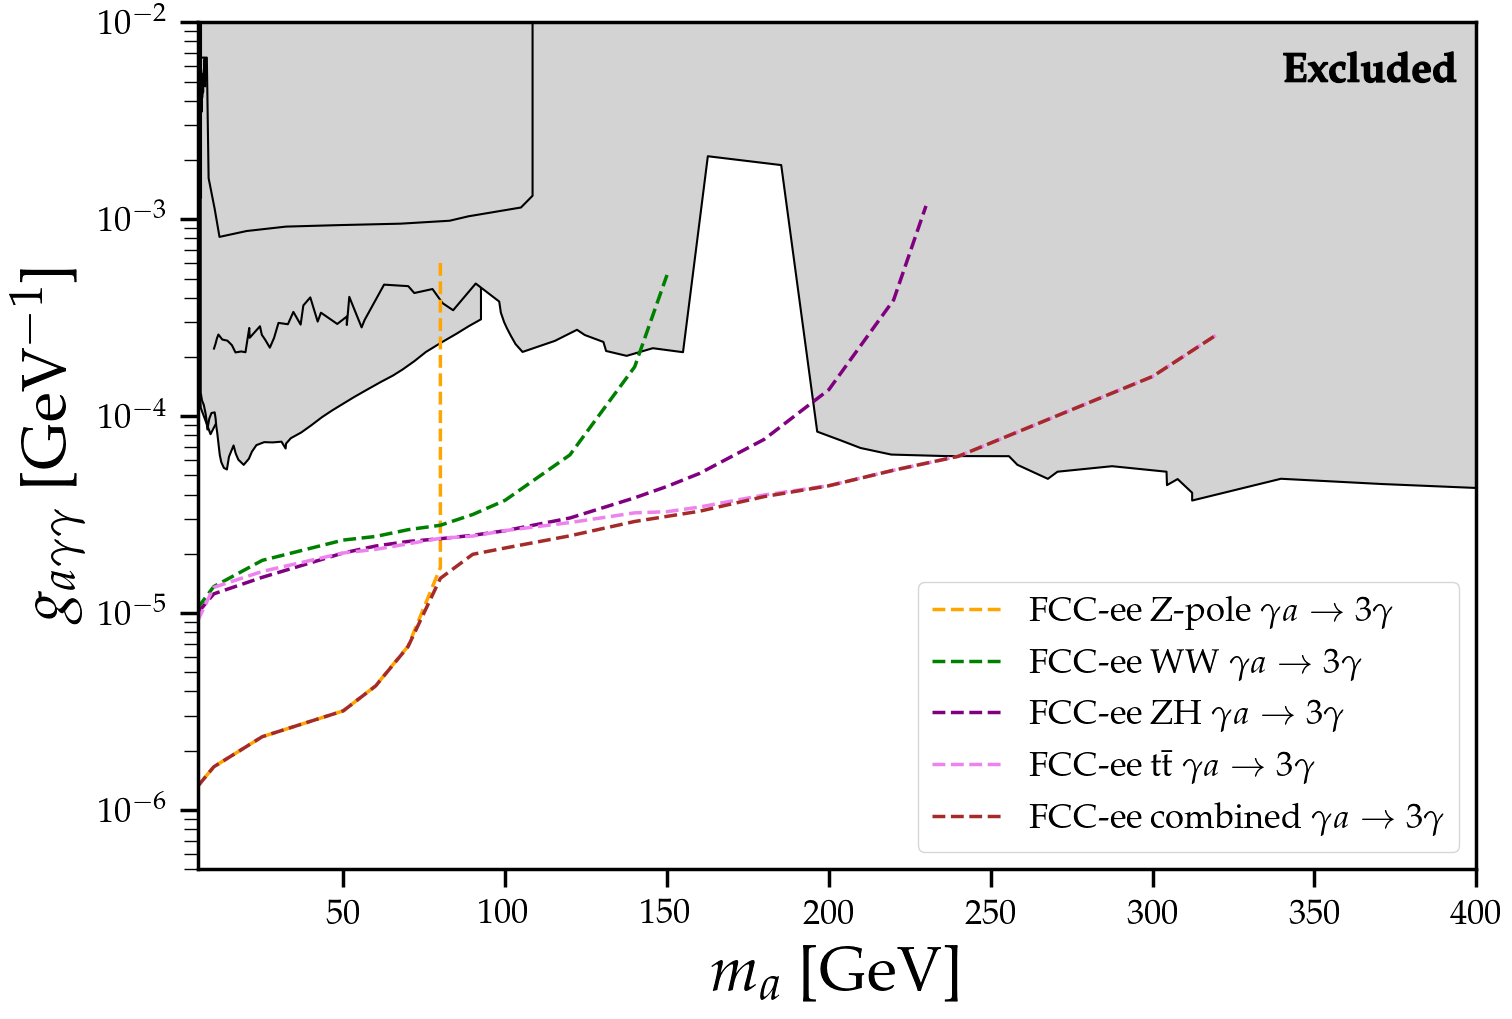

In [11]:
###### %matplotlib inline
import importlib
import PlotFuncs
importlib.reload(PlotFuncs)

from numpy import *
import matplotlib.pyplot as plt
from PlotFuncs import FigSetup, AxionPhoton, MySaveFig, BlackHoleSpins, FilledLimit

fig,ax = FigSetup(Shape='Rectangular',xlab=r'$m_a$ [GeV]',ylab=r'$g_{a\gamma\gamma}$ [GeV$^{-1}$]',mathpazo=True,
                  m_min=5e0,m_max=4e2,g_min=5e-7,g_max=1.0e-2,xtick_rotation=0)

ax.set_xscale('linear')

# m_min=1e-3,m_max=3e3
# g_min=1e-8,g_max=1.0e-1


def cme_91p188(ax):
    dat = loadtxt("limit_data/AxionPhoton/cme_91p188.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x[::-1], y[::-1], '--', color='orange',lw=2.5,label=r'{FCC-ee}  Z-pole  $\gamma a \rightarrow 3\gamma$')


def cme_160(ax):
    dat = loadtxt("limit_data/AxionPhoton/cme_160.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='green',lw=2.5,label=r'{FCC-ee}  WW  $\gamma a \rightarrow 3\gamma$')
    

def cme_240(ax):
    dat = loadtxt("limit_data/AxionPhoton/cme_240.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='purple',lw=2.5,label=r'{FCC-ee}  ZH  $\gamma a \rightarrow 3\gamma$')

    
def cme_365(ax):
    dat = loadtxt("limit_data/AxionPhoton/cme_365.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='violet',lw=2.5,label=r'{FCC-ee}  t$\bar{\mathrm{t}}$  $\gamma a \rightarrow 3\gamma$')


def combined(ax):
    dat = loadtxt("limit_data/AxionPhoton/combined.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='brown',lw=2.5,label=r'{FCC-ee}  combined  $\gamma a \rightarrow 3\gamma$')

    
# AxionPhoton.SNe_decay(ax,rotation=0,fs=30,text_pos=[1.5e7,8e-8])
# AxionPhoton.SN1987_PVO(ax,fs=20)
# AxionPhoton.DiffuseGammaRays(ax,text_pos=[2.5e5,5e-10],fs=21)

# AxionPhoton.BeamDump(ax,rotation=-45,fs=33,text_shift=[0.9,0.3])
# AxionPhoton.BaBar(ax)
# AxionPhoton.CMS_PbPb(ax,fs=30,text_shift=[1,0.8])
# AxionPhoton.ATLAS_PbPb(ax,fs=30,text_shift=[1,1.2])
# AxionPhoton.LHC_pp(ax,fs=28,text_col='w',text_shift=[1.7,10],path_effects=line_background(1.5,'k'))
# AxionPhoton.BelleII(ax,fs=30)
# AxionPhoton.PrimEx(ax,fs=20,text_shift=[0.85,0.9],rotation=90)
# AxionPhoton.LEP(ax,fs=35,text_shift=[1,0.2])
# AxionPhoton.BESIII(ax,fs=31,text_shift=[1.3,1.4])
# AxionPhoton.OPAL(ax,fs=24,text_shift=[0.021,3.5],text_col='w',path_effects=line_background(1.5,'k'))
# AxionPhoton.MiniBooNE(ax,text_shift=[1.5,0.45],fs=20,rotation=-43)
# AxionPhoton.GlueX(ax,text_shift=[1,0.1],fs=20)

# PlotBound(ax,"limit_data/AxionPhoton/FASER.txt",zorder=1.64,lw=1.5,facecolor='grey',y2=1e-3)
# plt.text(2.9e7,2.0e-4,r'{\bf FASER}',color='w',fontsize=17,rotation=-65,path_effects=line_background(1,'k'))

PlotBound(ax,"limit_data/AxionPhoton/SNe-decay.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/SN1987A_PVO.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/DiffuseGammaRays.txt",scale_x=1e-9,facecolor='lightgrey')

PlotBound(ax,"limit_data/AxionPhoton/BeamDump.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BaBar.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/CMS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/ATLAS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/CMS_TOTEM.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/LHC_pp.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BelleII.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/PrimEx.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/LEP.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/BESIII.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/OPAL.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/MiniBooNE.txt",scale_x=1e-9,facecolor='lightgrey')
PlotBound(ax,"limit_data/AxionPhoton/GlueX.txt",scale_x=1e-9,facecolor='lightgrey')

plt.text(3.4e2,5.0e-3,r'{\bf Excluded}',color='k',fontsize=30,rotation=0,path_effects=line_background(1,'k'))

# cme_91p188_full_line(ax)
cme_91p188(ax)
cme_160(ax)
cme_240(ax)
cme_365(ax)
combined(ax)

ax.legend(loc='lower right')

MySaveFig(fig,'limits_closeup.pdf')

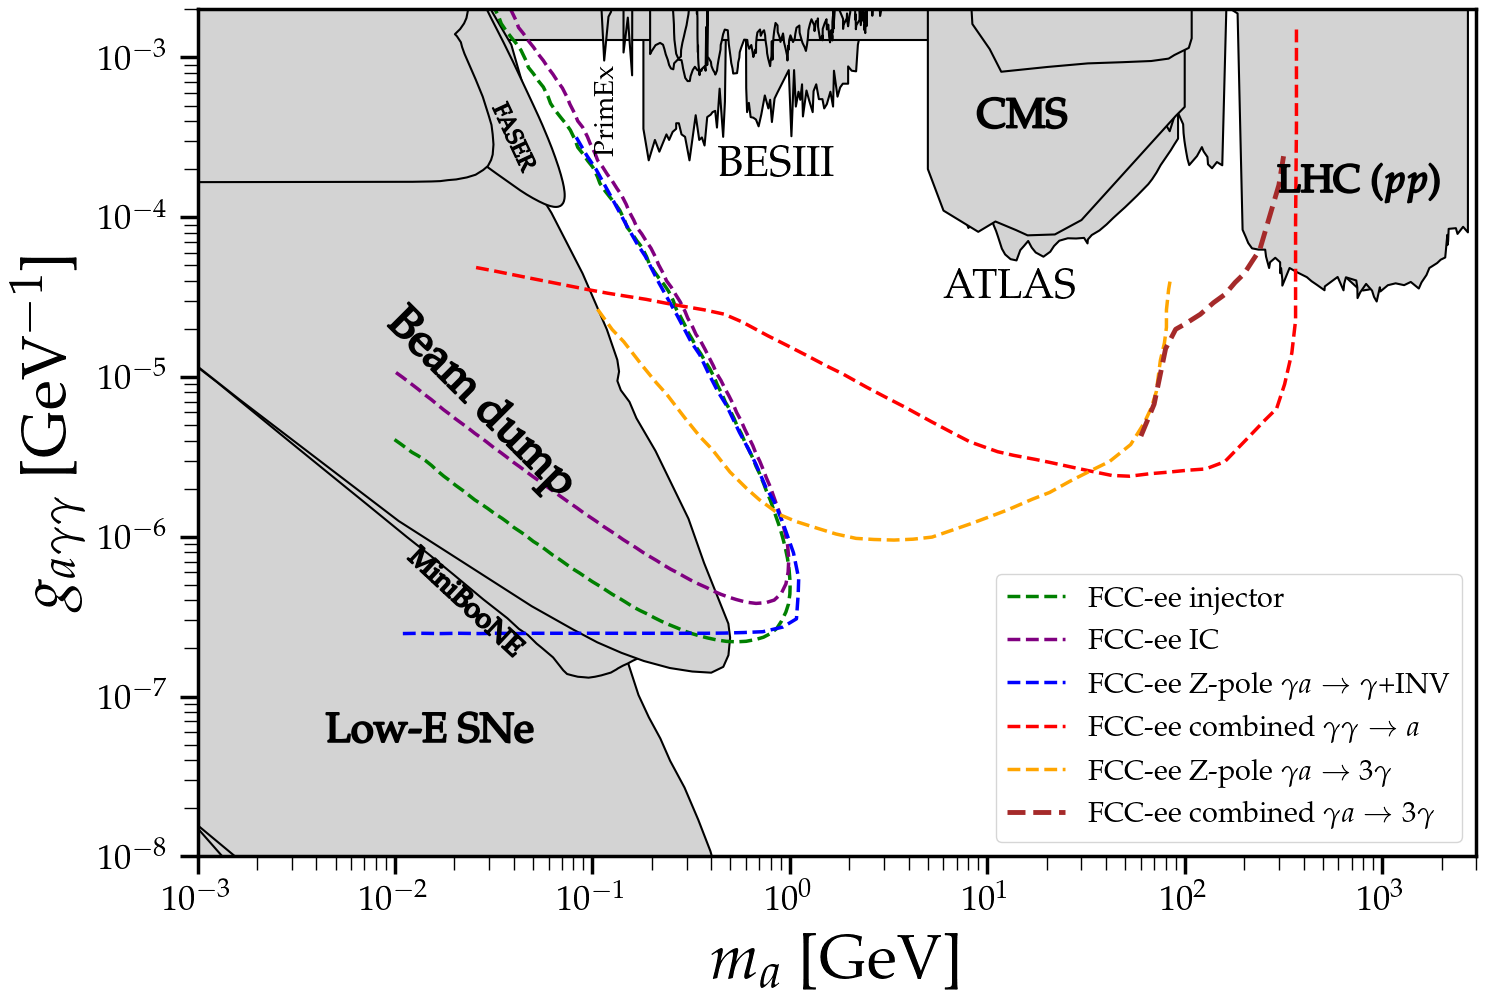

In [12]:
import importlib
import PlotFuncs
importlib.reload(PlotFuncs)
    
%matplotlib inline
from numpy import *
import matplotlib.pyplot as plt
from PlotFuncs import FigSetup, AxionPhoton, MySaveFig, BlackHoleSpins, FilledLimit

fig,ax = FigSetup(Shape='Rectangular',xlab=r'$m_a$ [GeV]',ylab=r'$g_{a\gamma\gamma}$ [GeV$^{-1}$]',mathpazo=True,
                  m_min=1e-3,m_max=3e3,g_min=1e-8,g_max=2.0e-3,xtick_rotation=0)

# m_min=1e-3,m_max=3e3
# g_min=1e-8,g_max=1.0e-1


def ga_to_ginv(ax):
    dat = loadtxt("limit_data/AxionPhoton/ga_to_ginv.txt")
    x = dat[:,0]
    y = dat[:,1]/(1e3)
    
    ax.plot(x, y, '--', color='blue',lw=2.5,label=r'{FCC-ee}  Z-pole  $\gamma a \rightarrow \gamma$+INV')
    

def giacomo_zpole(ax):
    dat = loadtxt("limit_data/AxionPhoton/giacomo_zpole.txt")
    x = dat[:,0]
    y = dat[:,1]/(1e3)
    
    ax.plot(x, y, '--', color='orange',lw=2.5,label=r'{FCC-ee}  Z-pole  $\gamma a \rightarrow 3\gamma$')


def fcc_injection(ax):
    dat = loadtxt("limit_data/AxionPhoton/fcc_injection.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='green',lw=2.5,label=r'{FCC-ee}  injector')


def fcc_IC(ax):
    dat = loadtxt("limit_data/AxionPhoton/fcc_IC.txt")
    x = dat[:,0]
    y = dat[:,1]
    
    ax.plot(x, y, '--', color='purple',lw=2.5,label=r'{FCC-ee}  IC')
    

def g_fusion(ax,ratio,c):
    dat = loadtxt("limit_data/AxionPhoton/g_fusion.txt")
    x = dat[:,0]
    y = dat[:,1]*(1/ratio)/(1e3)
    
    ax.plot(x, y, '--', color=c,lw=2.5,label=r'{FCC-ee}  combined  $\gamma \gamma \rightarrow a $')
    

def combined(ax, c):
    dat = loadtxt("limit_data/AxionPhoton/combined.txt")
    x = dat[:,0][4:]
    y = dat[:,1][4:]
    
    ax.plot(x, y, '--', color=c,lw=3.5,label=r'{FCC-ee}  combined  $\gamma a \rightarrow 3\gamma$')
    

AxionPhoton.SNe_decay(ax,rotation=0,fs=30,text_pos=[1.5e7,8e-8])
AxionPhoton.SN1987_PVO(ax,fs=20)
AxionPhoton.DiffuseGammaRays(ax,text_pos=[2.5e-4,5e-10],fs=21)

# PlotBound(ax,"limit_data/AxionPhoton/CMS_TOTEM.txt",scale_x=1e-9,zorder=1.64,lw=1.5,facecolor='lightgrey',y2=1e-3)
# PlotBound(ax,"limit_data/AxionPhoton/LHC_pp.txt",scale_x=1e-9,zorder=1.64,lw=1.5,facecolor='lightgrey',y2=1e-3)
# PlotBound(ax,"limit_data/AxionPhoton/CMS_PbPb.txt",scale_x=1e-9,zorder=1.64,lw=1.5,facecolor='lightgrey',y2=1e-3)
# PlotBound(ax,"limit_data/AxionPhoton/BelleII.txt",scale_x=1e-9,zorder=1.64,lw=1.5,facecolor='lightgrey',y2=1e-3)

AxionPhoton.BeamDump(ax,rotation=-45,fs=33,text_shift=[0.9,0.3])
AxionPhoton.BaBar(ax)
AxionPhoton.CMS_PbPb(ax,fs=30,text_shift=[1,0.8])
AxionPhoton.ATLAS_PbPb(ax,fs=30,text_shift=[1,1.2])
AxionPhoton.CMS_TOTEM(ax,fs=30,zorder=-0.1)
AxionPhoton.LHC_pp(ax,fs=28,text_col='k',text_shift=[1.7,10],path_effects=line_background(1.5,'k'))
AxionPhoton.BelleII(ax,fs=30)
AxionPhoton.PrimEx(ax,fs=20,text_shift=[0.85,0.9],rotation=90)
AxionPhoton.LEP(ax,fs=35,text_shift=[1,0.2])
AxionPhoton.BESIII(ax,fs=31,text_shift=[1.3,1.4])
AxionPhoton.OPAL(ax,fs=24,text_shift=[0.021,3.5],text_col='w',path_effects=line_background(1.5,'k'))
AxionPhoton.MiniBooNE(ax,text_shift=[1.5,0.45],fs=20,rotation=-43)
AxionPhoton.GlueX(ax,text_shift=[1,0.1],fs=20)

PlotBound(ax,"limit_data/AxionPhoton/FASER.txt",scale_x=1e-9,zorder=1.64,lw=1.5,facecolor='lightgrey',y2=1e-3)
plt.text(2.9e-2,2.0e-4,r'{FASER}',color='k',fontsize=17,rotation=-65,path_effects=line_background(1,'k'))

# PlotBound(ax,"limit_data/AxionPhoton/SNe-decay.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/SN1987A_PVO.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/DiffuseGammaRays.txt",scale_x=1e-9,facecolor='lightgrey')

# PlotBound(ax,"limit_data/AxionPhoton/BeamDump.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/BaBar.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/CMS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/ATLAS_PbPb.txt",scale_x=1e-9,facecolor='lightgrey')
# # PlotBound(ax,"limit_data/AxionPhoton/LHC_pp.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/BelleII.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/PrimEx.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/LEP.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/BESIII.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/OPAL.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/MiniBooNE.txt",scale_x=1e-9,facecolor='lightgrey')
# PlotBound(ax,"limit_data/AxionPhoton/GlueX.txt",scale_x=1e-9,facecolor='lightgrey')


fcc_injection(ax)
fcc_IC(ax)
ga_to_ginv(ax)
g_fusion(ax, 1, "red")
giacomo_zpole(ax)
combined(ax, "brown")


ax.legend(loc='lower right', fontsize='small')

MySaveFig(fig,'axion_photon_limits_all.pdf')